# 04 – Value model v2: per-game production

v1 (notebooks 02–03) learned that the market pays for **role and volume**: snap %, games, season totals.
That made missed games look like bad production, and efficient low-volume players look overpaid.
v2 asks a narrower question: **given how well a player produces *per game*, what would the market pay?**

| | v1 | v2 |
|---|---|---|
| Production features | season totals + usage (snaps, snap %, games) | **per game played**, 2-season weighted (2/3 current, 1/3 prior) |
| Consistency | – | share of good games + weekly yardage floor (RB/WR/TE) |
| Production score | – | position-specific composite of within-position percentiles (weights in `src/model.py`) |
| Constraints | none | **monotone**: predicted pay can only rise with production |
| Labels | one, with a 10-game rule | (a) **season**: per-game value, injury has no effect; (b) **3-year**: per-game value × availability |

Same evaluation as Phase 3: train 2019–2023 veterans, test 2024–2025, linear baseline, season-based CV.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

from src.model import (BEST_PARAMS, FEATURE_NAMES, MIN_GAMES, PAY_FLOOR, POSITIONS, PRODUCTION_WEIGHTS, TARGET, TRAIN_SEASONS,
                       V2_MIN_GAMES,
                       add_production_score, apply_contract_overrides, assign_labels, build_features, build_features_v2,
                       evaluate, implied_salary_cap, load_player_season, load_player_season_v2, monotone_constraints,
                       pay_tiers, season_cv_splits, shap_reasons, train_model)

FIG_DIR, EXPORT_DIR = ROOT / "docs" / "figures", ROOT / "exports"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

## 1. Data and the production score

`load_player_season_v2()` joins `player_season` to `player_season_pergame` (sql/07: per-game stats, consistency,
2-season weighting) and `player_availability` (sql/08). Daniel Jones 2024 gets the same documented contract
correction as v1. The production score uses the weights below (edit `PRODUCTION_WEIGHTS` in `src/model.py`).

In [2]:
df = add_production_score(apply_contract_overrides(load_player_season_v2()))
print(f"{len(df):,} player-seasons, {df.shape[1]} columns")
pd.DataFrame(PRODUCTION_WEIGHTS).fillna(0).style.format("{:.1%}")

2,402 player-seasons, 74 columns


,QB,RB/WR/TE
epa_pg,30.0%,20.0%
pass_yds_pg,25.0%,0.0%
pass_td_pg,20.0%,0.0%
cpoe,15.0%,0.0%
rush_yds_pg,10.0%,0.0%
yds_pg,0.0%,35.0%
rec_pg,0.0%,20.0%
good_game_share,0.0%,12.5%
floor_yards,0.0%,12.5%


In [3]:
# Sanity check: the top production scores per position in 2024
show = ["player_name", "position", "team", "games_played", "production_score", "w_epa_pg", "w_yds_pg", "w_rec_pg",
        "w_pass_yds_pg", "w_pass_td_pg"]
df[df["season"] == 2024].sort_values("production_score", ascending=False).groupby("position").head(4)[show].round(2)

,player_name,position,team,games_played,production_score,w_epa_pg,w_yds_pg,w_rec_pg,w_pass_yds_pg,w_pass_td_pg
1752,George Kittle,TE,SF,15,98.46,4.27,70.41,4.82,0.00,0.00
1859,Justin Jefferson,WR,MIN,17,98.13,3.98,95.92,6.31,0.86,0.00
1893,Ja'Marr Chase,WR,CIN,17,97.85,4.26,92.31,7.06,-0.15,0.00
2004,Puka Nacua,WR,LA,11,97.83,4.77,89.14,6.85,0.00,0.00
1935,Trey McBride,TE,ARI,16,97.67,2.26,63.93,6.21,0.00,0.00
1897,Amon-Ra St. Brown,WR,DET,17,96.95,5.31,81.09,6.99,0.27,0.04
2015,Brock Bowers,TE,LV,17,96.66,1.54,70.24,6.59,0.00,0.00
2005,Jahmyr Gibbs,RB,DET,17,95.80,1.60,103.67,3.19,0.00,0.00
1718,Travis Kelce,TE,KC,16,95.61,1.96,56.16,6.11,0.00,0.00
1955,Bijan Robinson,RB,ATL,17,92.26,0.21,102.69,3.53,0.00,0.00


## 2. Split, features and constraints

In [4]:
vets = df[~df["is_rookie_contract"]].reset_index(drop=True)
train = vets[vets["season"].isin(TRAIN_SEASONS)].reset_index(drop=True)
test = vets[vets["season"].isin([2024, 2025])].reset_index(drop=True)
train_contracts = set(zip(train["gsis_id"], train["contract_year_signed"]))
test["contract_seen_in_train"] = [(g, y) in train_contracts for g, y in zip(test["gsis_id"], test["contract_year_signed"])]

X_train, X_test = build_features_v2(train), build_features_v2(test)
X_train_lin, X_test_lin = build_features_v2(train, drop_first=True), build_features_v2(test, drop_first=True)
y_train, y_test = train[TARGET], test[TARGET]
cv_folds = season_cv_splits(train["season"], first_val_season=2021)
constraints = monotone_constraints(list(X_train.columns))

print(f"train {len(train):,} rows (2019–2023), test {len(test):,} rows (2024–2025); "
      f"{test['contract_seen_in_train'].sum()} test rows share a contract with training")
pd.DataFrame({"feature": X_train.columns, "monotone (+1 = pay can only rise)": constraints})

train 1,025 rows (2019–2023), test 413 rows (2024–2025); 71 test rows share a contract with training


,feature,monotone (+1 = pay can only rise)
0,position_QB,0
1,position_RB,0
2,position_WR,0
3,position_TE,0
4,age,0
5,w_pass_yds_pg,1
6,w_pass_td_pg,1
7,w_cpoe,1
8,w_rush_yds_pg,1
9,w_carries_pg,1


## 3. Baselines and the v2 XGBoost model

Same grid and season-based CV as Phase 3, now with the monotone constraints.

**Pay floor.** Every model's predictions are floored at `PAY_FLOOR` (0.3% of cap, the 1st percentile of veteran pay
in training, about the veteran minimum). Nobody can be paid less than the minimum, and v2's monotone trees can
extrapolate below zero for very poor per-game production.

In [5]:
floor = lambda pred: np.maximum(pred, PAY_FLOOR)

# Baseline 0: position average
pred_posavg = test["position"].map(train.groupby("position")[TARGET].mean()).to_numpy()

# Baseline 1: linear regression on the v2 features
linear = make_pipeline(StandardScaler(), LinearRegression())
cv_mae_lin = -cross_val_score(linear, X_train_lin, y_train, cv=cv_folds, scoring="neg_mean_absolute_error")
pred_lin = floor(linear.fit(X_train_lin, y_train).predict(X_test_lin))

# v2 XGBoost, tuned with season-based CV
param_grid = {"max_depth": [2, 3, 4], "learning_rate": [0.03, 0.1], "n_estimators": [200, 500], "min_child_weight": [1, 5]}
xgb_base = XGBRegressor(objective="reg:squarederror", subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=4,
                        monotone_constraints=constraints)
search = GridSearchCV(xgb_base, param_grid, cv=cv_folds, scoring="neg_mean_absolute_error").fit(X_train, y_train)
xgb_v2 = search.best_estimator_
print(f"raw v2 test predictions below the floor: {(xgb_v2.predict(X_test) < PAY_FLOOR).sum()}")
pred_v2 = floor(xgb_v2.predict(X_test))
print("v2 best params:", search.best_params_, f" season-CV MAE {-100 * search.best_score_:.3f} pp")

raw v2 test predictions below the floor: 41
v2 best params: {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 1, 'n_estimators': 500}  season-CV MAE 1.738 pp


In [6]:
# Check the constraint: raising any production feature never lowers a prediction
deltas = {}
for col in [c for c, k in zip(X_test.columns, constraints) if k == 1]:
    bumped = X_test.copy()
    bumped[col] = bumped[col] + X_train[col].std()
    deltas[FEATURE_NAMES[col]] = 100 * (xgb_v2.predict(bumped) - xgb_v2.predict(X_test)).min()
pd.Series(deltas, name="smallest change in prediction after +1 SD (pp)").round(4).to_frame()

,smallest change in prediction after +1 SD (pp)
Passing yards per game,0.099
Passing TDs per game,0.000
CPOE,0.000
Rushing yards per game,0.000
Carries per game,0.000
Receiving yards per game,0.000
Receptions per game,0.000
Targets per game,0.006
EPA per game,0.000
Success rate,0.000


### v1 on the same test rows

v1 is refit from `BEST_PARAMS` on the same training rows, with the same contract correction, so both models are
scored on identical data.

In [7]:
ps_v1 = apply_contract_overrides(load_player_season())
model_v1 = train_model(ps_v1)
v1_rows = ps_v1.set_index(["gsis_id", "season"]).loc[list(zip(test["gsis_id"], test["season"]))].reset_index()
pred_v1 = floor(model_v1.predict(build_features(v1_rows)))
assert (v1_rows[TARGET].to_numpy() == y_test.to_numpy()).all()   # same targets, same order

# Seed stability for both models (5 seeds, same settings)
def seed_range(make_model, X_tr, X_te):
    maes = [100 * mean_absolute_error(y_test, floor(make_model(s).fit(X_tr, y_train).predict(X_te))) for s in range(5)]
    return f"{min(maes):.3f}–{max(maes):.3f}"

X_train_v1 = build_features(ps_v1.set_index(["gsis_id", "season"]).loc[list(zip(train["gsis_id"], train["season"]))].reset_index())
seeds = {
    "XGBoost v1": seed_range(lambda s: XGBRegressor(objective="reg:squarederror", random_state=s, n_jobs=4, **BEST_PARAMS),
                             X_train_v1, build_features(v1_rows)),
    "XGBoost v2": seed_range(lambda s: XGBRegressor(objective="reg:squarederror", random_state=s, n_jobs=4, subsample=0.8,
                                                    colsample_bytree=0.8, monotone_constraints=constraints, **search.best_params_),
                             X_train, X_test),
}
seeds

{'XGBoost v1': '2.002–2.052', 'XGBoost v2': '1.785–1.808'}

## 4. Results: v1 vs v2 (test seasons 2024–2025, veteran contracts)

In [8]:
unseen = ~test["contract_seen_in_train"].to_numpy()
models = {"position average": pred_posavg, "linear v2": pred_lin, "XGBoost v1": pred_v1, "XGBoost v2": pred_v2}

summary = pd.DataFrame({
    name: {
        "R² (all)": evaluate(y_test, p, test["position"]).loc["all", "R2"],
        "MAE pp (all)": evaluate(y_test, p, test["position"]).loc["all", "MAE_pct_of_cap"],
        "R² (unseen contracts)": evaluate(y_test[unseen], p[unseen], test.loc[unseen, "position"]).loc["all", "R2"],
        "MAE pp (unseen contracts)": evaluate(y_test[unseen], p[unseen], test.loc[unseen, "position"]).loc["all", "MAE_pct_of_cap"],
    } for name, p in models.items()
}).T
summary["MAE range over 5 seeds"] = summary.index.map(seeds).fillna("–")
summary.round(3)

,R² (all),MAE pp (all),R² (unseen contracts),MAE pp (unseen contracts),MAE range over 5 seeds
position average,0.353,3.600,0.242,3.275,–
linear v2,0.702,2.068,0.690,1.754,–
XGBoost v1,0.705,1.991,0.670,1.766,2.002–2.052
XGBoost v2,0.753,1.793,0.692,1.630,1.785–1.808


In [9]:
# Per position
pd.concat({name: evaluate(y_test, p, test["position"]).drop(columns="n") for name, p in models.items()
           if name != "position average"}, axis=1).round(3)

linear v2                XGBoost v1                XGBoost v2               
             R2 MAE_pct_of_cap         R2 MAE_pct_of_cap         R2 MAE_pct_of_cap
group                                                                             
all       0.702          2.068      0.705          1.991      0.753          1.793
QB        0.414          6.003      0.417          5.384      0.516          4.767
RB        0.478          0.975      0.440          1.005      0.366          1.072
WR        0.685          1.812      0.712          1.744      0.762          1.555
TE        0.629          0.955      0.508          1.115      0.640          0.938

In [10]:
# Overfitting check
pd.DataFrame({
    "train MAE": [100 * mean_absolute_error(y_train, linear.predict(X_train_lin)),
                  100 * mean_absolute_error(y_train, xgb_v2.predict(X_train))],
    "season-CV MAE": [100 * cv_mae_lin.mean(), -100 * search.best_score_],
    "test MAE": [100 * mean_absolute_error(y_test, pred_lin), 100 * mean_absolute_error(y_test, pred_v2)],
}, index=["linear v2", "XGBoost v2"]).round(3)

,train MAE,season-CV MAE,test MAE
linear v2,1.950,2.066,2.068
XGBoost v2,1.198,1.738,1.793


## 5. What drives v2's valuation (SHAP)

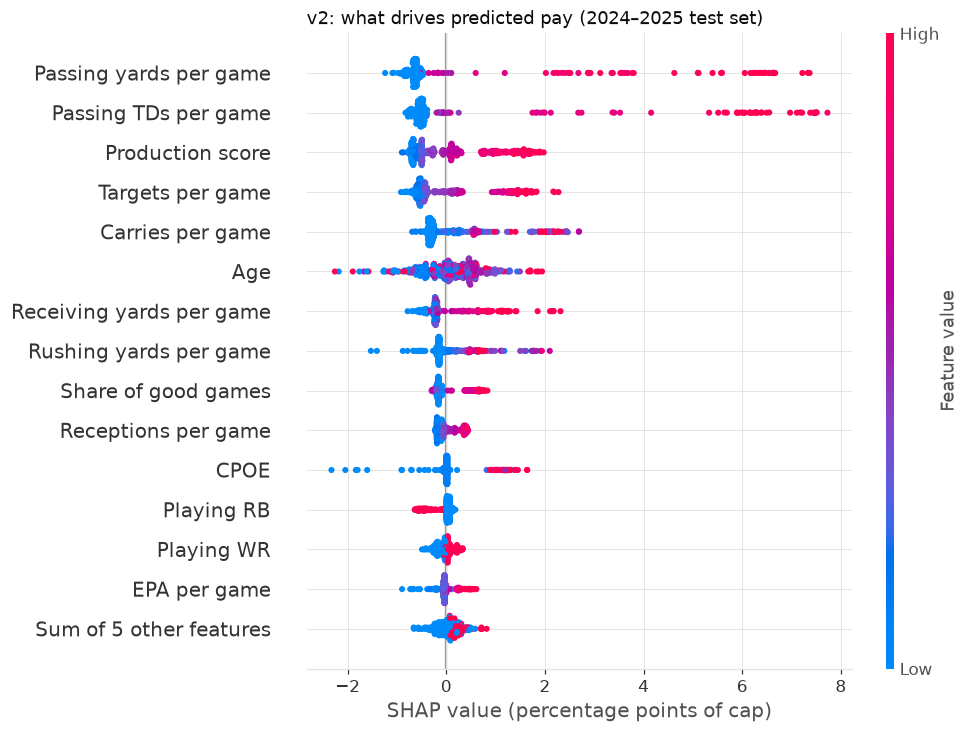

,mean |SHAP| (pp of cap)
Passing yards per game,1.096
Passing TDs per game,1.056
Production score,0.655
Targets per game,0.642
Carries per game,0.504
Age,0.470
Receiving yards per game,0.395
Rushing yards per game,0.282
Share of good games,0.242
Receptions per game,0.171


In [11]:
explainer = shap.TreeExplainer(xgb_v2)
sv_test = explainer(X_test)
to_pp = lambda e, X: shap.Explanation(values=e.values * 100, base_values=e.base_values * 100,
                                      data=X.to_numpy(), feature_names=[FEATURE_NAMES[c] for c in X.columns])
plt.figure()
shap.plots.beeswarm(to_pp(sv_test, X_test), max_display=15, show=False)
plt.gca().set_xlabel("SHAP value (percentage points of cap)")
plt.title("v2: what drives predicted pay (2024–2025 test set)", loc="left", fontsize=12)
plt.savefig(FIG_DIR / "v2_shap_summary.png")
plt.show()

pd.Series(np.abs(sv_test.values * 100).mean(axis=0), index=[FEATURE_NAMES[c] for c in X_test.columns]) \
  .sort_values(ascending=False).round(3).head(12).to_frame("mean |SHAP| (pp of cap)")

## 6. Score 2024–2025 and label

- **Fair value (season)** = v2 prediction from per-game production (floored at the minimum). Missing games don't change it.
- **Fair value (3-year)** = season fair value × availability over the current and two prior seasons
  (games played ÷ games possible).
- Both gaps are labeled the same way: within position × pay tier, top/bottom 15% and at least \\$2.5M.
- **Season label only:** a veteran with fewer than 6 games gets **Limited sample** instead of Overpaid or Underpaid.
  That's a sample-size rule (a handful of games is too noisy to call), not an injury penalty: the fair value itself
  still ignores missed games. The 3-year label has no game-count rule; availability already handles it there.
- **Durability concern**: availability under 75% in at least 2 of the last 3 seasons.

In [12]:
cap = implied_salary_cap([2024, 2025])
scored = df[df["season"].isin([2024, 2025])].copy()
X_scored = build_features_v2(scored)
scored["fair"] = floor(xgb_v2.predict(X_scored))
print(f"2024–2025 player-seasons floored at the minimum: {(xgb_v2.predict(X_scored) < PAY_FLOOR).sum()}")
scored["fair_3yr"] = scored["fair"] * scored["availability_3yr"]
scored["season_cap_musd"] = scored["season"].map(cap)

scored["actual_pct"] = 100 * scored[TARGET]
scored["actual_musd"] = scored[TARGET] * scored["season_cap_musd"]
for suffix, col in [("", "fair"), ("_3yr", "fair_3yr")]:
    scored[f"fair_pct{suffix}"] = 100 * scored[col]
    scored[f"fair_musd{suffix}"] = scored[col] * scored["season_cap_musd"]
    scored[f"gap_pp{suffix}"] = scored["actual_pct"] - scored[f"fair_pct{suffix}"]
    scored[f"gap_musd{suffix}"] = scored["actual_musd"] - scored[f"fair_musd{suffix}"]

scored["pay_tier"] = pay_tiers(scored)
groups = ["position", "pay_tier"]
scored["label_season"], scored["gap_pctile_season"] = assign_labels(scored, "gap_pp", "gap_musd", groups,
                                                                  limited_sample_games=V2_MIN_GAMES)
scored["label_3yr"], scored["gap_pctile_3yr"] = assign_labels(scored, "gap_pp_3yr", "gap_musd_3yr", groups)

order = ["Overpaid", "Fair", "Underpaid", "Limited sample", "Rookie contract"]
pd.concat({
    "season label": pd.crosstab(scored["label_season"], scored["position"]).reindex(order)[POSITIONS],
    "3-year label": pd.crosstab(scored["label_3yr"], scored["position"]).reindex(order)[POSITIONS],
}, axis=1).fillna(0).astype(int)

2024–2025 player-seasons floored at the minimum: 120


season label              3-year label             
position                  QB  RB   WR  TE           QB  RB   WR  TE
Overpaid                  12   6   18  11           12   7   18  11
Fair                      43  68  126  76           45  67  129  76
Underpaid                  7  12   19  14            6  12   16  14
Limited sample             1   0    0   0            0   0    0   0
Rookie contract           30  58  124  71           30  58  124  71

In [13]:
# Pay-tier check (as in v1): an unbiased rule flags the middle and top tiers at similar rates
vet = ~scored["is_rookie_contract"]
pd.concat({lab: pd.crosstab(scored.loc[vet, "pay_tier"], scored.loc[vet, lab], normalize="index")
              .reindex(index=["low", "mid", "high"], columns=["Overpaid", "Fair", "Underpaid"], fill_value=0) * 100
           for lab in ["label_season", "label_3yr"]}, axis=1).round(1)

label_season                 label_3yr                
label_season     Overpaid  Fair Underpaid  Overpaid  Fair Underpaid
pay_tier                                                           
low                   2.9  82.7      13.7       2.9  82.7      14.4
mid                  14.0  72.1      14.0      14.7  71.3      14.0
high                 17.4  72.5      10.1      17.4  76.1       6.5

In [14]:
# How the labels moved from v1 to v2 (season label). v1 is scored exactly as in notebook 03.
v1_scored = ps_v1[ps_v1["season"].isin([2024, 2025])].copy()
v1_scored["gap_pp"] = 100 * (v1_scored[TARGET] - model_v1.predict(build_features(v1_scored)))
v1_scored["gap_musd"] = v1_scored["gap_pp"] / 100 * v1_scored["season"].map(cap)
v1_scored["pay_tier"] = pay_tiers(v1_scored)
v1_scored["label_v1"], _ = assign_labels(v1_scored, "gap_pp", "gap_musd", groups, min_games=MIN_GAMES,
                                         min_games_for_underpaid=True)
v1_scored["fair_pct_v1"] = 100 * v1_scored[TARGET] - v1_scored["gap_pp"]
scored = scored.merge(v1_scored[["gsis_id", "season", "label_v1", "fair_pct_v1"]], on=["gsis_id", "season"], how="left")
vet = ~scored["is_rookie_contract"]   # recompute: the merge gave scored a new index
pd.crosstab(scored.loc[~scored["is_rookie_contract"], "label_v1"].rename("v1"),
            scored.loc[~scored["is_rookie_contract"], "label_season"].rename("v2 season"))

v2 season,Fair,Limited sample,Overpaid,Underpaid
v1,,,,
Fair,278,0,21,21
Injury-shortened,3,0,2,0
Limited sample,2,1,0,3
Overpaid,13,0,24,0
Underpaid,17,0,0,28


## 7. The lists

In [15]:
cols = ["player_name", "position", "season", "team", "games_played", "production_score", "w_epa_pg", "w_yds_pg",
        "actual_pct", "fair_pct", "gap_musd", "availability_3yr", "gap_musd_3yr", "label_3yr", "label_v1"]
print("TOP 15 OVERPAID VETERANS: season label (per-game value)")
scored[scored["label_season"] == "Overpaid"].nlargest(15, "gap_musd")[cols].round(2)

TOP 15 OVERPAID VETERANS: season label (per-game value)


,player_name,position,season,team,games_played,production_score,w_epa_pg,w_yds_pg,actual_pct,fair_pct,gap_musd,availability_3yr,gap_musd_3yr,label_3yr,label_v1
55,Deshaun Watson,QB,2024,CLE,7,25.43,-7.23,0.00,22.1,3.46,47.61,0.37,53.15,Overpaid,Injury-shortened
193,Trevor Lawrence,QB,2024,JAX,10,48.94,0.11,-0.33,21.5,6.08,39.37,0.84,41.81,Overpaid,Overpaid
352,Kirk Cousins,QB,2025,ATL,10,31.52,-0.07,0.00,17.6,5.60,33.47,0.63,39.28,Overpaid,Overpaid
459,Tua Tagovailoa,QB,2025,MIA,14,58.15,2.71,0.00,20.8,10.96,27.43,0.82,32.82,Fair,Fair
39,Dak Prescott,QB,2024,DAL,8,66.28,1.51,0.00,23.5,14.95,21.83,0.73,32.32,Overpaid,Fair
133,Daniel Jones,QB,2024,NYG,10,35.53,-4.16,0.00,17.8,9.56,21.06,0.63,30.15,Overpaid,Fair
377,Jared Goff,QB,2025,DET,17,86.20,7.13,0.14,20.8,14.04,18.86,1.00,18.86,Fair,Fair
73,Cooper Kupp,WR,2024,LA,12,71.46,0.47,59.92,12.8,5.99,17.38,0.65,22.79,Overpaid,Overpaid
3,Matthew Stafford,QB,2024,LA,16,56.70,2.88,0.00,19.2,12.85,16.21,0.78,23.29,Overpaid,Overpaid
413,Christian Kirk,WR,2025,HOU,13,42.65,-0.69,28.05,8.6,2.99,15.66,0.65,18.59,Overpaid,Overpaid


In [16]:
print("TOP 15 UNDERPAID VETERANS: season label")
scored[scored["label_season"] == "Underpaid"].nsmallest(15, "gap_musd")[cols].round(2)

TOP 15 UNDERPAID VETERANS: season label


,player_name,position,season,team,games_played,production_score,w_epa_pg,w_yds_pg,actual_pct,fair_pct,gap_musd,availability_3yr,gap_musd_3yr,label_3yr,label_v1
5,Russell Wilson,QB,2024,PIT,11,60.85,-0.39,0.00,0.5,19.61,-48.80,0.80,-38.98,Underpaid,Underpaid
2,Joe Flacco,QB,2024,IND,8,58.83,-0.86,0.00,1.8,16.34,-37.14,0.35,-10.14,Underpaid,Fair
450,Daniel Jones,QB,2025,IND,13,65.76,3.54,0.00,5.0,11.91,-19.27,0.57,-4.94,Fair,Underpaid
102,Baker Mayfield,QB,2024,TB,17,85.21,5.68,0.00,13.1,19.61,-16.63,0.90,-11.72,Underpaid,Underpaid
347,Aaron Rodgers,QB,2025,PIT,16,48.15,0.85,-0.38,4.9,10.37,-15.26,0.67,-5.62,Fair,Underpaid
222,Rashid Shaheed,WR,2024,NO,6,59.03,-0.29,54.76,1.2,6.80,-14.29,0.65,-8.16,Underpaid,Limited sample
65,Jonnu Smith,TE,2024,MIA,17,91.74,2.43,46.08,1.6,6.11,-11.52,0.94,-10.60,Underpaid,Underpaid
454,J.K. Dobbins,RB,2025,DEN,10,66.08,-0.30,81.06,0.7,4.63,-10.96,0.47,-4.12,Underpaid,Underpaid
105,Jakobi Meyers,WR,2024,LV,15,82.90,1.85,62.46,4.9,9.14,-10.84,0.88,-8.09,Underpaid,Fair
138,J.K. Dobbins,RB,2024,LAC,13,70.03,-0.74,81.38,0.6,4.81,-10.75,0.43,-3.77,Underpaid,Fair


In [17]:
print("TOP 15 OVERPAID VETERANS: 3-year label (per-game value × availability)")
cols3 = ["player_name", "position", "season", "team", "games_played", "games_3yr", "availability_3yr", "durability_concern",
         "production_score", "actual_pct", "fair_pct", "fair_pct_3yr", "gap_musd_3yr", "label_season"]
scored[scored["label_3yr"] == "Overpaid"].nlargest(15, "gap_musd_3yr")[cols3].round(2)

TOP 15 OVERPAID VETERANS: 3-year label (per-game value × availability)


,player_name,position,season,team,games_played,games_3yr,availability_3yr,durability_concern,production_score,actual_pct,fair_pct,fair_pct_3yr,gap_musd_3yr,label_season
55,Deshaun Watson,QB,2024,CLE,7,19.0,0.37,True,25.43,22.1,3.46,1.29,53.15,Overpaid
193,Trevor Lawrence,QB,2024,JAX,10,43.0,0.84,False,48.94,21.5,6.08,5.13,41.81,Overpaid
352,Kirk Cousins,QB,2025,ATL,10,32.0,0.63,True,31.52,17.6,5.60,3.51,39.28,Overpaid
431,Kyler Murray,QB,2025,ARI,5,30.0,0.59,True,55.22,22.1,13.96,8.21,38.72,Fair
39,Dak Prescott,QB,2024,DAL,8,37.0,0.73,True,66.28,23.5,14.95,10.85,32.32,Overpaid
133,Daniel Jones,QB,2024,NYG,10,32.0,0.63,True,35.53,17.8,9.56,6.00,30.15,Overpaid
3,Matthew Stafford,QB,2024,LA,16,40.0,0.78,False,56.70,19.2,12.85,10.08,23.29,Overpaid
73,Cooper Kupp,WR,2024,LA,12,33.0,0.65,True,71.46,12.8,5.99,3.88,22.79,Overpaid
0,Aaron Rodgers,QB,2024,NYJ,17,35.0,0.69,False,52.66,16.7,12.97,8.90,19.92,Fair
413,Christian Kirk,WR,2025,HOU,13,33.0,0.65,True,42.65,8.6,2.99,1.93,18.59,Overpaid


In [18]:
print("TOP 15 ROOKIE-CONTRACT SURPLUS (fair value − pay, season)")
rk = scored[scored["is_rookie_contract"]].assign(surplus_musd=lambda d: -d["gap_musd"], surplus_3yr_musd=lambda d: -d["gap_musd_3yr"])
rk.nlargest(15, "surplus_musd")[["player_name", "position", "season", "team", "games_played", "production_score",
                                  "actual_pct", "fair_pct", "surplus_musd", "availability_3yr", "surplus_3yr_musd"]].round(2)

TOP 15 ROOKIE-CONTRACT SURPLUS (fair value − pay, season)


,player_name,position,season,team,games_played,production_score,actual_pct,fair_pct,surplus_musd,availability_3yr,surplus_3yr_musd
235,Brock Purdy,QB,2024,SF,15,83.30,0.4,21.41,53.67,0.78,41.87
629,Drake Maye,QB,2025,NE,17,86.96,3.6,21.97,51.22,0.88,44.01
621,Bo Nix,QB,2025,DEN,17,69.67,1.8,19.71,49.94,1.00,49.94
322,Bo Nix,QB,2024,DEN,17,69.36,1.8,18.86,43.56,1.00,43.56
340,Jayden Daniels,QB,2024,WAS,17,75.85,3.7,19.46,40.24,1.00,40.24
597,Puka Nacua,WR,2025,LA,16,99.91,0.5,11.65,31.09,0.86,26.63
641,Caleb Williams,QB,2025,CHI,17,55.00,3.9,14.03,28.24,1.00,28.24
298,Puka Nacua,WR,2024,LA,11,97.83,0.5,11.14,27.17,0.82,22.15
595,Rashee Rice,WR,2025,KC,8,93.13,0.7,10.33,26.84,0.55,13.86
559,Jaxon Smith-Njigba,WR,2025,SEA,17,99.03,1.6,11.02,26.28,1.00,26.28


In [19]:
print("DURABILITY CONCERN (availability < 75% in at least 2 of the last 3 seasons), veterans")
dur = scored[vet & scored["durability_concern"]]
print(f"{len(dur)} veteran player-seasons flagged")
dur.sort_values("actual_musd", ascending=False)[["player_name", "position", "season", "team", "games_played", "games_3yr",
    "availability_3yr", "production_score", "actual_pct", "fair_pct", "fair_pct_3yr", "label_season", "label_3yr"]].head(15).round(2)

DURABILITY CONCERN (availability < 75% in at least 2 of the last 3 seasons), veterans
96 veteran player-seasons flagged


,player_name,position,season,team,games_played,games_3yr,availability_3yr,production_score,actual_pct,fair_pct,fair_pct_3yr,label_season,label_3yr
478,Joe Burrow,QB,2025,CIN,8,35.0,0.69,83.91,24.5,20.41,14.01,Fair,Fair
431,Kyler Murray,QB,2025,ARI,5,30.0,0.59,55.22,22.1,13.96,8.21,Fair,Overpaid
39,Dak Prescott,QB,2024,DAL,8,37.0,0.73,66.28,23.5,14.95,10.85,Overpaid,Overpaid
55,Deshaun Watson,QB,2024,CLE,7,19.0,0.37,25.43,22.1,3.46,1.29,Overpaid,Overpaid
112,Kyler Murray,QB,2024,ARI,17,36.0,0.71,61.91,22.1,17.92,12.65,Fair,Fair
352,Kirk Cousins,QB,2025,ATL,10,32.0,0.63,31.52,17.6,5.60,3.51,Overpaid,Overpaid
133,Daniel Jones,QB,2024,NYG,10,32.0,0.63,35.53,17.8,9.56,6.00,Overpaid,Overpaid
73,Cooper Kupp,WR,2024,LA,12,33.0,0.65,71.46,12.8,5.99,3.88,Overpaid,Overpaid
473,Tee Higgins,WR,2025,CIN,15,39.0,0.76,89.64,10.3,8.32,6.36,Fair,Fair
169,Nico Collins,WR,2024,HOU,12,37.0,0.73,95.05,9.5,10.28,7.46,Fair,Fair


## 8. Eye test: v1 vs v2

The players from the brief, plus two chronically injured players chosen by rule (not by hand):
- the durability-flagged veteran with the **highest production score** (productive whenever he plays)
- the **highest-paid** durability-flagged veteran whose season and 3-year labels **disagree** (shows what the
  availability adjustment changes)

In [20]:
chronic_best = dur.sort_values("production_score", ascending=False).iloc[0]
chronic_split = dur[dur["label_season"] != dur["label_3yr"]].sort_values("actual_pct", ascending=False).iloc[0]
for why, r in [("highest production score", chronic_best), ("highest-paid with disagreeing labels", chronic_split)]:
    print(f"chronically injured ({why}): {r['player_name']} {r['season']}")
eye = [("Amon-Ra St. Brown", 2024), ("Lamar Jackson", 2025), ("Josh Allen", 2024), ("Josh Allen", 2025),
       ("Justin Jefferson", 2024), ("Saquon Barkley", 2024),
       (chronic_best["player_name"], chronic_best["season"]), (chronic_split["player_name"], chronic_split["season"])]
keys = pd.DataFrame(eye, columns=["player_name", "season"])
eye_cols = ["player_name", "position", "season", "games_played", "production_score", "actual_pct", "fair_pct_v1", "label_v1",
            "fair_pct", "label_season", "availability_3yr", "durability_concern", "fair_pct_3yr", "label_3yr"]
keys.merge(scored, on=["player_name", "season"])[eye_cols].round(2)

chronically injured (highest production score): Nico Collins 2024
chronically injured (highest-paid with disagreeing labels): Kyler Murray 2025


,player_name,position,season,games_played,production_score,actual_pct,fair_pct_v1,label_v1,fair_pct,label_season,availability_3yr,durability_concern,fair_pct_3yr,label_3yr
0,Amon-Ra St. Brown,WR,2024,17,96.95,11.7,6.77,Overpaid,10.67,Fair,0.96,False,10.25,Fair
1,Lamar Jackson,QB,2025,13,78.70,23.1,9.38,Overpaid,19.48,Fair,0.90,False,17.57,Fair
2,Josh Allen,QB,2024,17,82.34,23.6,10.86,Fair,23.75,Fair,0.98,False,23.29,Fair
3,Josh Allen,QB,2025,17,80.11,19.7,12.75,Overpaid,21.64,Fair,1.00,False,21.64,Fair
4,Justin Jefferson,WR,2024,17,98.13,13.7,9.21,Fair,9.52,Fair,0.86,False,8.21,Fair
5,Saquon Barkley,RB,2024,16,89.27,4.9,6.86,Fair,6.38,Fair,0.90,False,5.76,Fair
6,Nico Collins,WR,2024,12,95.05,9.5,6.95,Fair,10.28,Fair,0.73,True,7.46,Fair
7,Kyler Murray,QB,2025,5,55.22,22.1,9.48,Fair,13.96,Fair,0.59,True,8.21,Overpaid


In [21]:
# Why: the top-3 SHAP reasons behind each eye-test player's v2 fair value
scored["top_reasons"] = shap_reasons(explainer(X_scored).values * 100, X_scored)
keys.merge(scored, on=["player_name", "season"])[["player_name", "season", "fair_pct", "top_reasons"]] \
    .style.set_properties(subset=["top_reasons"], **{"text-align": "left", "white-space": "normal"})

,player_name,season,fair_pct,top_reasons
0,Amon-Ra St. Brown,2024,10.671989,Receiving yards per game 81.1 (+2.2 pts of cap); Production score 97.0 (+1.9 pts of cap); Targets per game 8.9 (+1.8 pts of cap)
1,Lamar Jackson,2025,19.481928,Passing TDs per game 1.9 (+7.5 pts of cap); Passing yards per game 212.5 (+2.9 pts of cap); Carries per game 6.2 (+2.3 pts of cap)
2,Josh Allen,2024,23.752806,Passing TDs per game 1.7 (+7.5 pts of cap); Passing yards per game 230.7 (+6.2 pts of cap); Carries per game 6.2 (+2.4 pts of cap)
3,Josh Allen,2025,21.637093,Passing TDs per game 1.5 (+7.5 pts of cap); Passing yards per game 217.0 (+3.4 pts of cap); Carries per game 6.4 (+2.4 pts of cap)
4,Justin Jefferson,2024,9.515127,Receiving yards per game 95.9 (+2.1 pts of cap); Production score 98.1 (+2.0 pts of cap); Targets per game 9.4 (+1.8 pts of cap)
5,Saquon Barkley,2024,6.383771,Carries per game 20.3 (+2.1 pts of cap); Production score 89.3 (+1.7 pts of cap); Passing yards per game 0.0 (−0.8 pts of cap)
6,Nico Collins,2024,10.284415,Receiving yards per game 84.7 (+2.1 pts of cap); Production score 95.1 (+1.9 pts of cap); Targets per game 7.9 (+1.7 pts of cap)
7,Kyler Murray,2025,13.962348,Passing TDs per game 1.2 (+3.4 pts of cap); Passing yards per game 203.8 (+3.4 pts of cap); Carries per game 5.4 (+2.1 pts of cap)


## 9. Teams

In [22]:
def team_totals(d: pd.DataFrame) -> pd.Series:
    out = {}
    for suffix, lab in [("", "label_season"), ("_3yr", "label_3yr")]:
        gap = d[f"gap_musd{suffix}"]
        out[f"overpaid{suffix}_musd"] = gap[d[lab] == "Overpaid"].sum()
        out[f"n_overpaid{suffix}"] = (d[lab] == "Overpaid").sum()
        out[f"underpaid_surplus{suffix}_musd"] = -gap[d[lab] == "Underpaid"].sum()
        out[f"n_underpaid{suffix}"] = (d[lab] == "Underpaid").sum()
        out[f"rookie_surplus{suffix}_musd"] = -gap[d[lab] == "Rookie contract"].sum()
        out[f"net_value{suffix}_musd"] = (out[f"underpaid_surplus{suffix}_musd"] + out[f"rookie_surplus{suffix}_musd"]
                                          - out[f"overpaid{suffix}_musd"])
    out["n_rookie"] = d["is_rookie_contract"].sum()
    out["n_durability_concern"] = (d["durability_concern"] & ~d["is_rookie_contract"]).sum()
    out["durability_concern_pay_musd"] = d.loc[d["durability_concern"] & ~d["is_rookie_contract"], "actual_musd"].sum()
    return pd.Series(out)

team_season = scored.groupby(["team", "season"]).apply(team_totals, include_groups=False).reset_index()
count_cols = [c for c in team_season.columns if c.startswith("n_")]
team_season[count_cols] = team_season[count_cols].astype(int)
team_season[[c for c in team_season.columns if c.endswith("_musd")]] += 0.0   # -0.0 -> 0.0

team_both = team_season.drop(columns="season").groupby("team").sum()
print("2024 + 2025 combined: net value by season label and by 3-year label ($M)")
team_both[["net_value_musd", "net_value_3yr_musd", "overpaid_musd", "underpaid_surplus_musd", "rookie_surplus_musd",
           "n_durability_concern"]].sort_values("net_value_musd", ascending=False).round(1)

2024 + 2025 combined: net value by season label and by 3-year label ($M)


,net_value_musd,net_value_3yr_musd,overpaid_musd,underpaid_surplus_musd,rookie_surplus_musd,n_durability_concern
team,,,,,,
DEN,116.9,105.9,0.0,18.3,98.6,2
PIT,108.7,80.2,4.3,78.7,34.4,0
IND,100.5,41.3,0.0,56.4,44.1,4
NO,93.8,48.3,0.0,35.2,58.5,2
TB,79.6,63.4,0.0,29.2,50.4,3
WAS,68.2,46.4,13.7,21.3,60.6,5
NE,66.0,56.9,11.0,10.3,66.7,2
LAC,64.6,47.2,0.0,10.8,53.9,5
SF,54.4,21.7,29.9,24.9,59.4,4


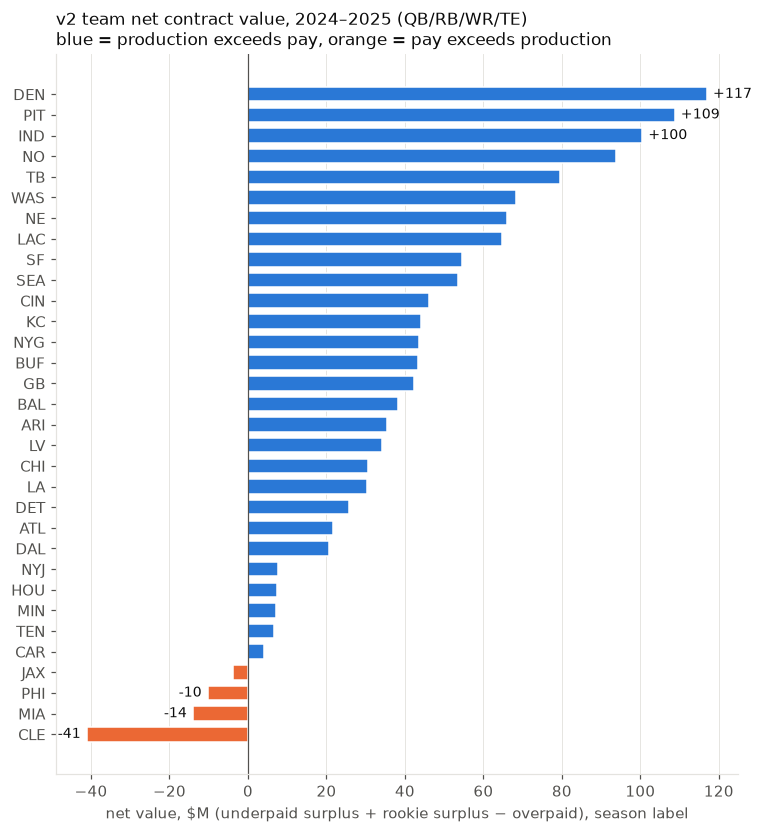

In [23]:
fig, ax = plt.subplots(figsize=(8, 8.5))
t = team_both["net_value_musd"].sort_values()
ax.barh(t.index, t.values, color=np.where(t >= 0, BLUE, ORANGE), height=0.7, edgecolor="white", linewidth=1)
ax.axvline(0, color=MUTED, linewidth=0.8)
for name in list(t.index[:3]) + list(t.index[-3:]):
    v = t[name]
    ax.annotate(f"{v:+.0f}", (v, name), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=9, color=INK)
ax.grid(axis="y", visible=False)
ax.set_xlabel("net value, $M (underpaid surplus + rookie surplus − overpaid), season label")
ax.set_title("v2 team net contract value, 2024–2025 (QB/RB/WR/TE)\nblue = production exceeds pay, orange = pay exceeds production",
             loc="left", fontsize=11)
fig.savefig(FIG_DIR / "v2_team_net_value.png")
plt.show()

## 10. Exports for Tableau

In [24]:
reasons = scored["top_reasons"].str.split("; ", expand=True).reindex(columns=range(3))
scored[["reason_1", "reason_2", "reason_3"]] = reasons.to_numpy()

per_game = ["pass_yds_pg", "pass_td_pg", "rush_yds_pg", "carries_pg", "rec_yds_pg", "rec_pg", "targets_pg",
            "scrim_yds_pg", "epa_pg", "success_rate", "epa_per_play", "cpoe"]
weighted = ["w_pass_yds_pg", "w_pass_td_pg", "w_rush_yds_pg", "w_rec_yds_pg", "w_yds_pg", "w_rec_pg", "w_targets_pg",
            "w_carries_pg", "w_epa_pg", "w_success_rate", "w_epa_per_play", "w_cpoe", "w_good_game_share", "w_floor_yards"]
percentiles = [c for c in scored.columns if c.startswith("pct_")]
player_cols = (
    ["season", "player_name", "gsis_id", "position", "team", "age", "games_played", "is_rookie_contract", "contract_type",
     "contract_year_signed", "apy", "season_cap_musd", "pay_tier", "production_score",
     "label_season", "actual_pct", "fair_pct", "gap_pp", "actual_musd", "fair_musd", "gap_musd", "gap_pctile_season",
     "label_3yr", "availability", "availability_3yr", "games_3yr", "possible_games_3yr", "durability_concern",
     "fair_pct_3yr", "gap_pp_3yr", "fair_musd_3yr", "gap_musd_3yr", "gap_pctile_3yr",
     "label_v1", "fair_pct_v1", "has_prior_season"]
    + per_game + ["good_game_share", "floor_yards"] + weighted + percentiles
    + ["reason_1", "reason_2", "reason_3", "override_reason"]
)
player_value = (scored[player_cols]
                .rename(columns={"apy": "apy_musd", "actual_pct": "actual_pct_of_cap", "fair_pct": "fair_pct_of_cap",
                                 "fair_pct_3yr": "fair_pct_of_cap_3yr", "fair_pct_v1": "fair_pct_of_cap_v1"})
                .sort_values(["season", "gap_musd"], ascending=[True, False]))
player_value.round(4).to_csv(EXPORT_DIR / "player_value.csv", index=False)
team_season.round(3).to_csv(EXPORT_DIR / "team_value.csv", index=False)

sv_scored = explainer(X_scored).values * 100
abs_shap = pd.DataFrame(np.abs(sv_scored), columns=X_scored.columns, index=scored.index)
imp = [abs_shap.mean().rename("all")] + [abs_shap[scored["position"] == p].mean().rename(p) for p in POSITIONS]
shap_importance = (pd.concat(imp, axis=1).reset_index(names="feature")
                   .melt(id_vars="feature", var_name="position", value_name="mean_abs_shap_pp"))
shap_importance.insert(1, "feature_name", shap_importance["feature"].map(FEATURE_NAMES))
shap_importance.round(4).to_csv(EXPORT_DIR / "shap_importance.csv", index=False)

for f in ["player_value.csv", "team_value.csv", "shap_importance.csv"]:
    d = pd.read_csv(EXPORT_DIR / f)
    print(f"exports/{f}: {len(d):,} rows x {d.shape[1]} cols")

exports/player_value.csv: 696 rows x 77 cols
exports/team_value.csv: 64 rows x 17 cols
exports/shap_importance.csv: 95 rows x 4 cols


## Observations

Every number below is printed by a cell above.

**Fixes made while building v2** (each found through the eye test or SHAP reasons):
1. *Prior seasons need 4+ games* (sql/07). Aaron Rodgers' 1-game 2023 (Achilles) dragged his weighted passing yards
   from about 229 to 153 per game and his fair value to the floor.
2. *Stats from another position are set to 0.* Trevor Lawrence's −0.3 receiving yards per game (a caught deflection)
   cost him 6 points of cap, because nearly every other QB has exactly 0 there.
3. *Pay floor at 0.3% of cap.* Monotone trees extrapolated below zero for very poor per-game production
   (120 of 696 scored player-seasons sit at the floor).

**v1 vs v2 (test 2024–2025, 413 veteran player-seasons, same rows and contract correction for both).**
- XGBoost v2: R² 0.753, MAE 1.79 pp (5 seeds: 1.785–1.808).
- XGBoost v1: R² 0.705, MAE 1.99 pp (5 seeds: 2.002–2.052).
- Unseen contracts only: v2 R² 0.692 / MAE 1.63 pp vs v1 0.670 / 1.77.
- v2 is better on every measure, and the seed ranges don't overlap. By position, v2 improves QB (R² 0.516 vs 0.417),
  WR (0.762 vs 0.712) and TE (0.640 vs 0.508), but is **worse at RB** (0.366 vs 0.440; linear v2 gets 0.478). RB pay
  tracks workload and role, which v1's snap % captured and per-game stats only partly do.
- v2 also overfits less: train/CV/test MAE 1.20 / 1.74 / 1.79 vs v1's 0.83 / 1.94 / 2.04. The monotone constraints
  act as regularization.

**What drives v2 (mean |SHAP|, pp of cap):** passing yards per game 1.10, passing TDs per game 1.06, production
score 0.66, targets per game 0.64, carries per game 0.50, age 0.47. No production feature can lower predicted pay.

**Labels.** Season label: 47 Overpaid, 313 Fair, 52 Underpaid, 1 Limited sample (Carson Wentz 2025, 5 games; the
6-game rule changed no one else). 3-year label: 48 / 317 / 48. 96 veteran
player-seasons carry the durability flag. Pay-tier check (season label, Overpaid %): low 2.9, mid 14.0, high 17.4.

**Eye test: v2 fixes v1's misses.** St. Brown 2024 (v1 Overpaid → Fair, worth 10.7% vs paid 11.7%), Lamar Jackson 2025
(Overpaid → Fair, 19.5% vs 23.1%), Josh Allen 2025 (Overpaid → Fair, 21.6% vs 19.7%), Josh Allen 2024 (Fair, 23.8% vs 23.6%),
Saquon Barkley 2024 (Fair, 6.4% vs 4.9%). The two chronically injured examples show what the 3-year label adds: Nico Collins 2024
(12 games, production score 95) is Fair either way, but his availability-adjusted value drops from 10.3% to 7.5%;
**Kyler Murray 2025** (5 games) is Fair per game but **Overpaid** over 3 years (worth 8.2% after availability vs paid 22.1%).

**Still looks off, and why:**
- **Justin Jefferson 2024** is labeled Fair but valued at 9.5% vs paid 13.7% (about \$10.7M over). The market pays a
  premium for the very best player at a position that per-game stats from 2019–2023 don't capture (the 2024 WR market
  reset). The label is Fair because the rule compares him with other top-tier WRs, who show similar gaps.
- **Short-stint backup QBs look underpaid on the season label**: Joe Flacco 2024 (8 games, −0.86 EPA/game, worth 16.3%)
  is Underpaid. QB value is driven mostly by passing *volume* per game, so any starter looks valuable per game. Carson
  Wentz 2025 (5 games, worth 11.2%) would have been too, but falls under the 6-game Limited sample rule.
- **Russell Wilson 2024** remains the most underpaid (\$48.8M): Pittsburgh paid a minimum deal while Denver paid the rest.
- **Elite QBs are still compressed**: Jared Goff 2025 (production score 86) is worth 14.0% vs paid 20.8%, labeled Fair.

**Teams (net \$M, 2024+2025, season label).** Best: DEN +116.9, PIT +108.7, IND +100.5, NO +93.8, TB +79.6.
Worst: CLE −41.1, MIA −14.0, PHI −10.2, JAX −3.8, CAR +4.1. On the 3-year label, teams with injured
starters fall: NYJ +7.7 → −35.0, IND +100.5 → +41.3, ARI +35.4 → −8.4.